<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/05_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================
# NOTEBOOK 5: FINAL MODEL EVALUATION
# Step 1: Setup and load saved results
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# Mount Google Drive
drive.mount("/content/drive")

# Project paths
PROJECT_DIR = (
    "/content/drive/MyDrive/fraud-detection-research"
)

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

# Load saved experiment results
baseline_path = os.path.join(
    RESULTS_DIR, "baseline_model_results.csv"
)

xgb_path = os.path.join(
    RESULTS_DIR, "xgboost_model_results.csv"
)

stacking_path = os.path.join(
    RESULTS_DIR, "stacking_model_results.csv"
)

dcs_path = os.path.join(
    RESULTS_DIR, "final_model_comparison.csv"
)

baseline_results = pd.read_csv(baseline_path)
xgb_results = pd.read_csv(xgb_path)
stacking_results = pd.read_csv(stacking_path)
final_comparison = pd.read_csv(dcs_path)

print("Experiment results loaded successfully.")

print("\nBaseline results:")
display(baseline_results)

print("\nXGBoost results:")
display(xgb_results)

print("\nStandard Stacking results:")
display(stacking_results)

print("\nFinal model comparison:")
display(final_comparison)


Mounted at /content/drive
Experiment results loaded successfully.

Baseline results:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.135782,0.697143,0.227294,0.845861,0.393141
1,Random Forest,0.383590,0.534286,0.446567,0.890110,0.508111



XGBoost results:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (Average Precision)
0,XGBoost,0.218803,0.731429,0.336842,0.897744,0.518671



Standard Stacking results:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (Average Precision)
0,Dynamic Stacking,0.18056,0.782857,0.29344,0.902864,0.547521



Final model comparison:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.1358,0.6971,0.2273,0.8459,0.3931
1,Random Forest,0.3836,0.5343,0.4466,0.8901,0.5081
2,XGBoost,0.2188,0.7314,0.3368,0.8977,0.5187
3,Standard Stacking,0.1806,0.7829,0.2934,0.9029,0.5475
4,Dynamic Classifier Selection,0.3112,0.4957,0.3824,0.7969,0.3808


In [ ]:
baseline_results = pd.read_csv(
    os.path.join(RESULTS_DIR, "baseline_model_results.csv")
)

xgb_results = pd.read_csv(
    os.path.join(RESULTS_DIR, "xgboost_model_results.csv")
)

stacking_results = pd.read_csv(
    os.path.join(RESULTS_DIR, "stacking_model_results.csv")
)

comparison_results = pd.read_csv(
    os.path.join(RESULTS_DIR, "final_model_comparison.csv")
)

print("BASELINE RESULTS")
display(baseline_results)

print("XGBOOST RESULTS")
display(xgb_results)

print("STACKING RESULTS")
display(stacking_results)

print("FINAL MODEL COMPARISON")
display(comparison_results)

BASELINE RESULTS


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.135782,0.697143,0.227294,0.845861,0.393141
1,Random Forest,0.383590,0.534286,0.446567,0.890110,0.508111


XGBOOST RESULTS


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (Average Precision)
0,XGBoost,0.218803,0.731429,0.336842,0.897744,0.518671


STACKING RESULTS


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC (Average Precision)
0,Dynamic Stacking,0.18056,0.782857,0.29344,0.902864,0.547521


FINAL MODEL COMPARISON


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.1358,0.6971,0.2273,0.8459,0.3931
1,Random Forest,0.3836,0.5343,0.4466,0.8901,0.5081
2,XGBoost,0.2188,0.7314,0.3368,0.8977,0.5187
3,Standard Stacking,0.1806,0.7829,0.2934,0.9029,0.5475
4,Dynamic Classifier Selection,0.3112,0.4957,0.3824,0.7969,0.3808


In [ ]:
prediction_path = os.path.join(
    RESULTS_DIR, "final_model_predictions.npz"
)

if not os.path.exists(prediction_path):
    raise FileNotFoundError(
        "Prediction file not found. Check that Notebook 4 saved "
        "final_model_predictions.npz in the results folder."
    )

predictions = np.load(prediction_path)

y_test = predictions["y_test"]

model_probabilities = {
    "Logistic Regression": predictions["logistic_regression_prob"],
    "Random Forest": predictions["random_forest_prob"],
    "XGBoost": predictions["xgboost_prob"],
    "Standard Stacking": predictions["stacking_prob"],
    "DCS": predictions["dcs_prob"]
}

# DCS has its own predicted class labels from its selection procedure.
dcs_pred = predictions["dcs_pred"]

print("Predictions loaded successfully.")
print("Test observations:", len(y_test))
print("Fraud cases:", int(np.sum(y_test)))
print("Models:", list(model_probabilities.keys()))

Predictions loaded successfully.
Test observations: 20000
Fraud cases: 700
Models: ['Logistic Regression', 'Random Forest', 'XGBoost', 'Standard Stacking', 'DCS']


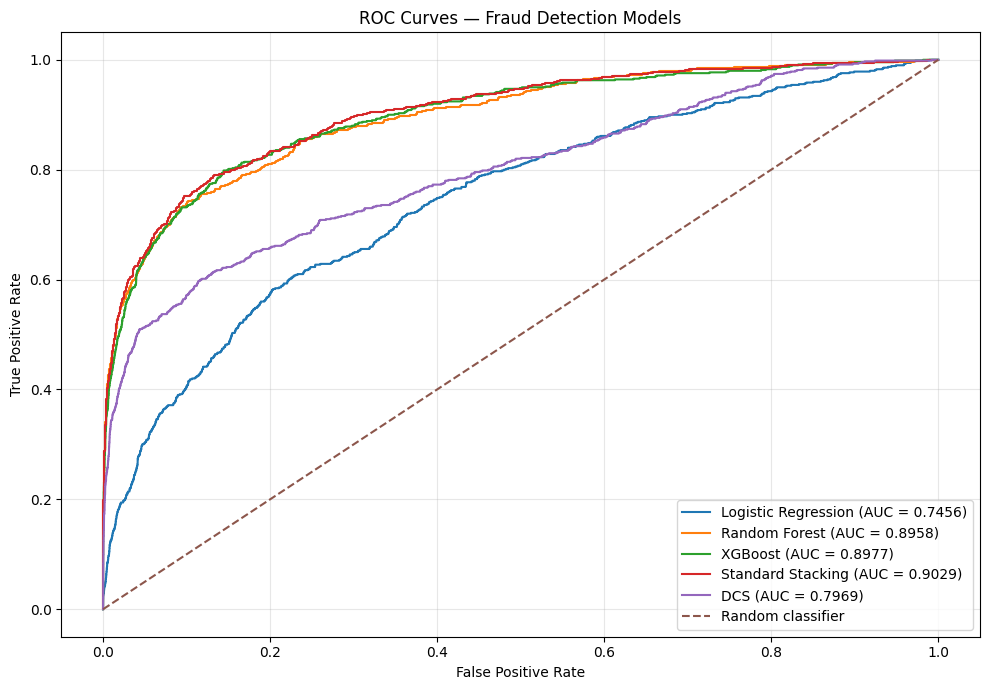

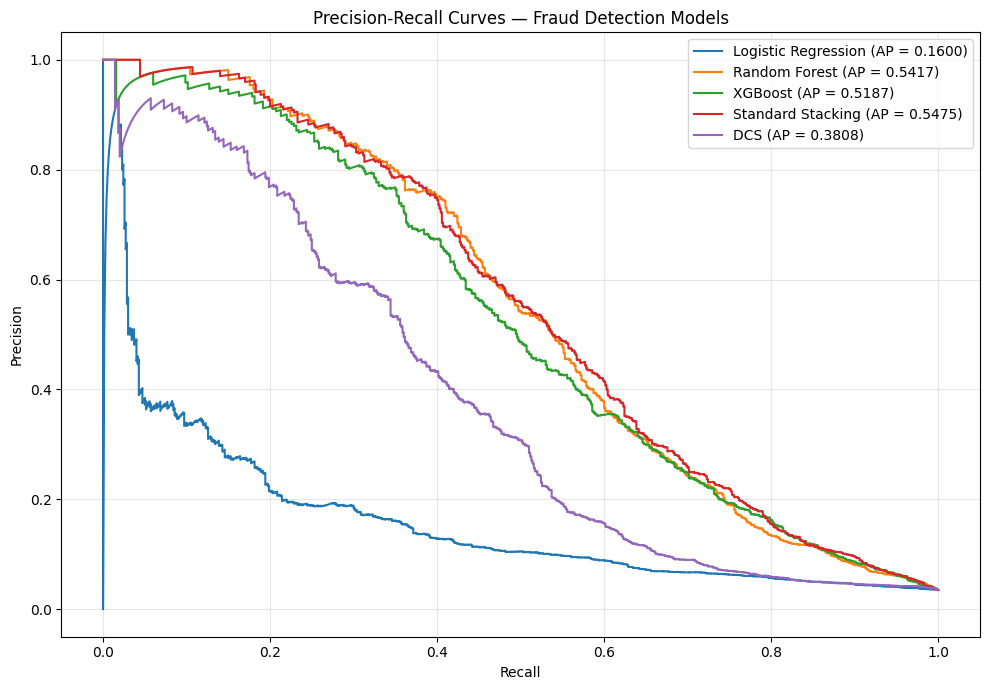

In [ ]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    roc_auc_value = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc_value:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Fraud Detection Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "roc_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(10, 7))

for model_name, probabilities in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )
    ap = average_precision_score(y_test, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Fraud Detection Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "precision_recall_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

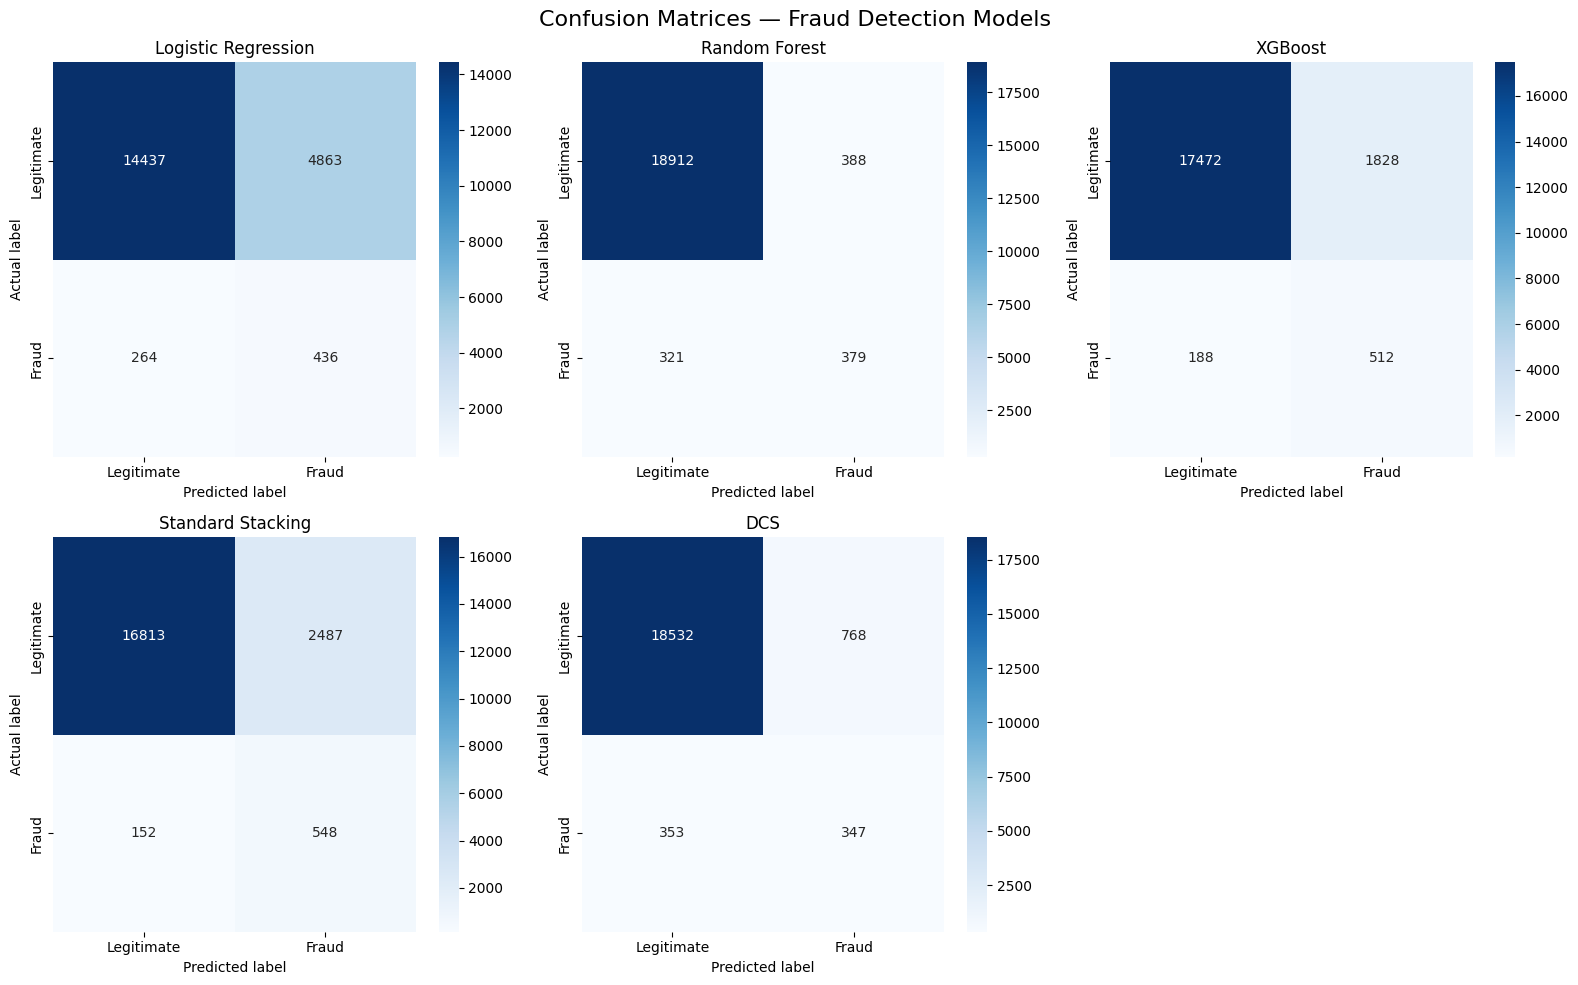

In [ ]:
model_predictions = {
    name: (probabilities >= 0.5).astype(int)
    for name, probabilities in model_probabilities.items()
}

model_predictions["DCS"] = dcs_pred.astype(int)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (model_name, predicted_labels) in enumerate(
    model_predictions.items()
):
    cm = confusion_matrix(y_test, predicted_labels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted label")
    axes[i].set_ylabel("Actual label")

# Hide the unused sixth panel.
axes[-1].axis("off")

plt.suptitle("Confusion Matrices — Fraud Detection Models", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
for model_name, predicted_labels in model_predictions.items():
    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            predicted_labels,
            target_names=["Legitimate", "Fraud"],
            digits=4,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

  Legitimate     0.9820    0.7480    0.8492     19300
       Fraud     0.0823    0.6229    0.1454       700

    accuracy                         0.7437     20000
   macro avg     0.5322    0.6854    0.4973     20000
weighted avg     0.9506    0.7437    0.8246     20000


Random Forest
              precision    recall  f1-score   support

  Legitimate     0.9833    0.9799    0.9816     19300
       Fraud     0.4941    0.5414    0.5167       700

    accuracy                         0.9646     20000
   macro avg     0.7387    0.7607    0.7492     20000
weighted avg     0.9662    0.9646    0.9653     20000


XGBoost
              precision    recall  f1-score   support

  Legitimate     0.9894    0.9053    0.9455     19300
       Fraud     0.2188    0.7314    0.3368       700

    accuracy                         0.8992     20000
   macro avg     0.6041    0.8184    0.6411     20000
weighted avg     0.9624    0.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


In [ ]:
evaluation_rows = []

for model_name, probabilities in model_probabilities.items():
    predicted_labels = model_predictions[model_name]

    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predicted_labels),
        "Precision": precision_score(
            y_test, predicted_labels, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicted_labels, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predicted_labels, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

evaluation_results = pd.DataFrame(evaluation_rows)

evaluation_results = evaluation_results.round(4)

display(evaluation_results)

evaluation_results.to_csv(
    os.path.join(RESULTS_DIR, "final_evaluation_metrics.csv"),
    index=False
)

print("Final evaluation metrics saved.")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7436,0.0823,0.6229,0.1454,0.7456,0.1600
1,Random Forest,0.9646,0.4941,0.5414,0.5167,0.8958,0.5417
2,XGBoost,0.8992,0.2188,0.7314,0.3368,0.8977,0.5187
3,Standard Stacking,0.8680,0.1806,0.7829,0.2934,0.9029,0.5475
4,DCS,0.9440,0.3112,0.4957,0.3824,0.7969,0.3808


Final evaluation metrics saved.


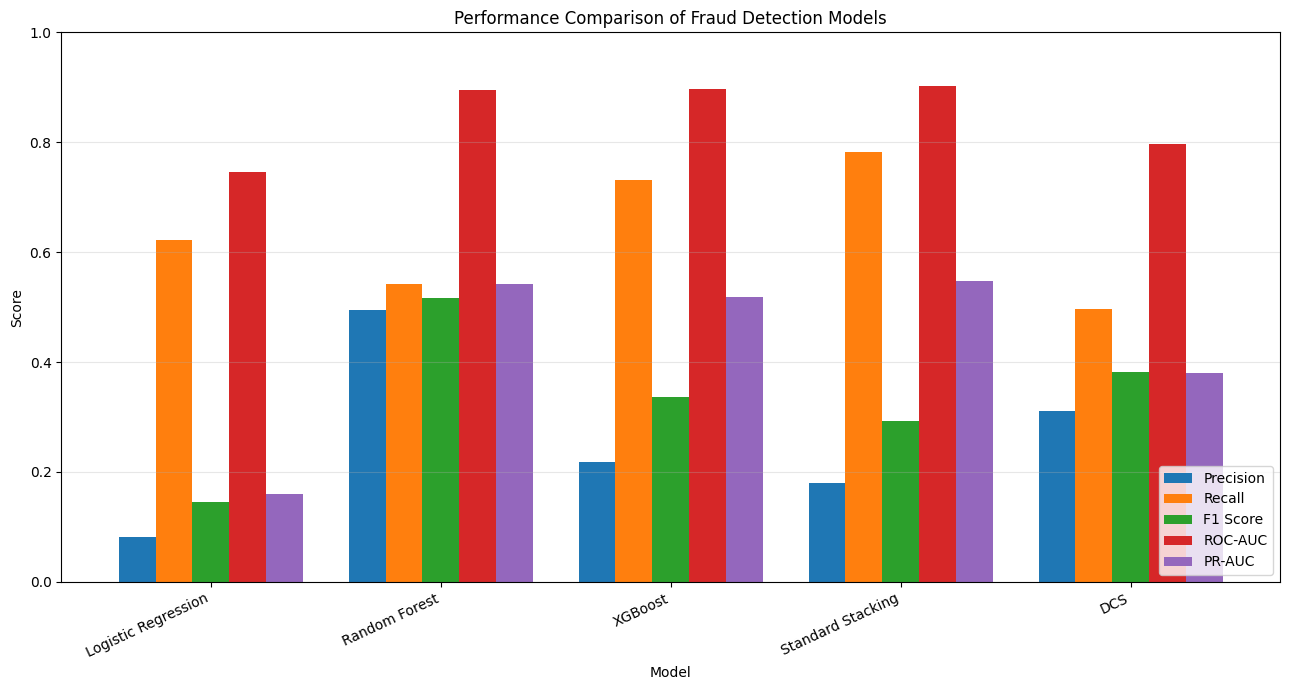

In [ ]:
metrics_to_plot = ["Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]

plot_data = evaluation_results.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

ax.set_title("Performance Comparison of Fraud Detection Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "model_performance_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
summary_path = os.path.join(
    RESULTS_DIR, "final_evaluation_summary.txt"
)

best_f1_model = evaluation_results.loc[
    evaluation_results["F1 Score"].idxmax()
]

best_roc_model = evaluation_results.loc[
    evaluation_results["ROC-AUC"].idxmax()
]

best_pr_model = evaluation_results.loc[
    evaluation_results["PR-AUC"].idxmax()
]

with open(summary_path, "w") as file:
    file.write("FRAUD DETECTION MODEL EVALUATION\n")
    file.write("=" * 50 + "\n\n")

    file.write(f"Test observations: {len(y_test)}\n")
    file.write(f"Fraud cases: {int(np.sum(y_test))}\n\n")

    file.write(
        f"Best F1 Score: {best_f1_model['Model']} "
        f"({best_f1_model['F1 Score']:.4f})\n"
    )
    file.write(
        f"Best ROC-AUC: {best_roc_model['Model']} "
        f"({best_roc_model['ROC-AUC']:.4f})\n"
    )
    file.write(
        f"Best PR-AUC: {best_pr_model['Model']} "
        f"({best_pr_model['PR-AUC']:.4f})\n\n"
    )

    file.write("FULL EVALUATION TABLE\n")
    file.write(evaluation_results.to_string(index=False))

print("Evaluation summary saved:", summary_path)

print("\nRESULTS FOLDER CONTENTS:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print(filename)

Evaluation summary saved: /content/drive/MyDrive/fraud-detection-research/results/final_evaluation_summary.txt

RESULTS FOLDER CONTENTS:
baseline_model_results.csv
confusion_matrices.png
final_evaluation_metrics.csv
final_evaluation_summary.txt
final_model_comparison.csv
final_model_predictions.npz
model_performance_comparison.png
precision_recall_curves.png
roc_curves.png
stacking_model_results.csv
stacking_threshold_results.csv
xgboost_model_results.csv
xgboost_threshold_results.csv
